# Exportación para la web · Análogos de Marte y de la Luna
Convierte los resultados de las **versiones activas** en archivos listos para el front y el back:
Marte (`04_resultados/version_activa.json`, secciones 1–7) y Luna (`04_resultados/version_activa_luna.json`, secciones 8–10).
No descarga nada de NASA: solo lee lo que generaron `EDA_analogos_v1.3.ipynb` y `EDA_luna_v0.3.ipynb`.

| Archivo (en `06_web/<versión>/`) | Para | Contenido |
|---|---|---|
| `regiones.geojson` | front | polígonos de las regiones candidatas (top 10 por perfil) con sus atributos |
| `analogos.geojson` | front | puntos de los análogos de la ficha, con datos publicados y de satélite |
| `indice_<perfil>.png` | front | capa raster del índice en **Web Mercator** (EPSG:3857), transparente donde no hay dato |
| `leyenda.json` | front | colores de la capa raster |
| `celdas.parquet` | back | una fila por celda de tierra: perfil, percentil y variables, para consultas por coordenada |
| `manifest.json` | ambos | versión, descripción de perfiles, archivos, límites de las imágenes y validación |
| `06_web/manifest.json` | ambos | copia del manifest de Marte + bloque `cuerpos` con la carpeta y el manifest de cada cuerpo (punto de entrada fijo) |
| `06_web/<versión luna>/…` | ambos | lo mismo para la Luna: `regiones.geojson`, `analogos.geojson`, `indice_luna.png`, `leyenda.json`, `celdas.parquet`, `manifest.json` |

## 1. Configuración y carga

In [ ]:
import os, json, datetime, shutil
import numpy as np, pandas as pd, xarray as xr
import matplotlib, matplotlib.pyplot as plt
from scipy import ndimage
from shapely.geometry import box, mapping, Polygon, MultiPolygon
from shapely.geometry.polygon import orient
from shapely.ops import unary_union
from PIL import Image
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
RESULTADOS, ANALOGOS, PROCESADOS = f"{BASE}/04_resultados", f"{BASE}/05_analogos", f"{BASE}/03_datos/procesados"

activa = json.load(open(f"{RESULTADOS}/version_activa.json", encoding="utf-8"))
VER = activa["version_activa"]
DIR_VER = f"{RESULTADOS}/{VER}"
WEB = f"{BASE}/06_web/{VER}"
os.makedirs(WEB, exist_ok=True)

indices = xr.open_dataset(f"{DIR_VER}/indices_perfiles_{VER}.nc").load()
clim = xr.open_dataset(f"{PROCESADOS}/clima_merra2_2014_2023.nc").load()
registro = json.load(open(f"{DIR_VER}/registro_{VER}.json", encoding="utf-8"))
LEER = dict(keep_default_na=False, na_values=[""])          # "NA" (Namibia) no es un valor vacío
ficha = pd.read_csv(f"{ANALOGOS}/ficha_analogos_completa.csv", **LEER)
comparacion = pd.read_csv(f"{RESULTADOS}/comparacion_versiones.csv")
codigos = {int(k): v for k, v in json.loads(indices["perfil_id"].attrs["codigos"]).items()}
PERFILES = [codigos[k] for k in sorted(codigos) if k > 0]
def leer_regiones(p):
    try:
        return pd.read_csv(f"{DIR_VER}/regiones_{p}_{VER}.csv", **LEER)
    except pd.errors.EmptyDataError:
        return pd.DataFrame(columns=["region_id", "rango", "lat", "lon"])
regiones_csv = {p: leer_regiones(p) for p in PERFILES}
UMBRAL_PCT = activa.get("umbral_regiones", 95)
print(f"Versión activa: {VER} | perfiles: {PERFILES} | umbral de regiones: p{UMBRAL_PCT}")

Mounted at /content/drive
Versión activa: v1.3 | perfiles: ['marte_polar', 'marte_altura', 'marte_arido'] | umbral de regiones: p95


In [ ]:
# Textos para la interfaz (español e inglés)
INFO_PERFILES = {
    "marte_polar": {"nombre": "Marte polar", "name_en": "Polar Mars",
                    "descripcion": "Desiertos polares fríos y secos con veranos que no deshielan (|lat| ≥ 60°).",
                    "description_en": "Cold, dry polar deserts with summers that stay frozen (|lat| ≥ 60°)."},
    "marte_altura": {"nombre": "Marte de altura", "name_en": "High-altitude Mars",
                     "descripcion": "Mesetas frías y secas por encima de 2500 m, con menos presión y más radiación UV.",
                     "description_en": "Cold, dry plateaus above 2,500 m, with lower pressure and more UV."},
    "marte_arido": {"nombre": "Marte árido", "name_en": "Arid Mars",
                    "descripcion": "Desiertos hiperáridos con suelo desnudo y fuertes contrastes térmicos.",
                    "description_en": "Hyper-arid deserts with bare ground and strong temperature swings."},
}

## 2. Regiones candidatas → `regiones.geojson`
Se reconstruyen las regiones etiquetando las celdas ≥ umbral (mismo método que el EDA) y se comprueba que cada región del CSV
coincide con su etiqueta antes de convertirla en polígono.

In [ ]:
lats, lons = indices.lat.values, indices.lon.values
DLAT, DLON = abs(lats[1] - lats[0]), abs(lons[1] - lons[0])
LAT2, LON2 = np.meshgrid(lats, lons, indexing="ij")

def limpio(v):
    """Valores aptos para JSON (sin NaN ni tipos de numpy)."""
    if isinstance(v, (float, np.floating)):
        return None if np.isnan(v) else round(float(v), 4)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, str) and v == "":
        return None
    return v

def orientar(geom):
    """RFC 7946: anillo exterior en sentido antihorario."""
    if isinstance(geom, Polygon):
        return orient(geom, 1.0)
    return MultiPolygon([orient(g, 1.0) for g in geom.geoms])

def redondear(geom, nd=4):
    def r(coords): return [[round(x, nd), round(y, nd)] for x, y in coords]
    g = mapping(geom)
    if g["type"] == "Polygon":
        g["coordinates"] = [r(anillo) for anillo in g["coordinates"]]
    else:
        g["coordinates"] = [[r(anillo) for anillo in poli] for poli in g["coordinates"]]
    return g

features, etiquetas_por_perfil = [], {}
for perfil in PERFILES:
    pct = indices[f"{perfil}_pct"].transpose("lat", "lon").values
    etiquetas, _ = ndimage.label(np.nan_to_num(pct, nan=0) >= UMBRAL_PCT, structure=np.ones((3, 3)))
    etiquetas_por_perfil[perfil] = etiquetas
    for r in regiones_csv[perfil].itertuples():
        m = etiquetas == r.region_id
        i, j = int(np.abs(lats - r.lat).argmin()), int(np.abs(lons - r.lon).argmin())
        assert m[i, j], f"{perfil} región {r.region_id}: la etiqueta no coincide con el CSV (¿cambió el umbral?)"
        celdas = [box(lo - DLON / 2, la - DLAT / 2, lo + DLON / 2, la + DLAT / 2) for la, lo in zip(LAT2[m], LON2[m])]
        geom = orientar(unary_union(celdas))
        props = {"id": f"{perfil}-{r.rango}", "perfil": perfil, **INFO_PERFILES[perfil],
                 "rango": int(r.rango), "region": r.region, "pais_iso": r.pais_iso,
                 "percentil_max": r.percentil_max, "percentil_medio": r.percentil_medio,
                 "area_km2": r.area_km2, "n_celdas": r.n_celdas,
                 "mejor_celda": [round(r.lon, 4), round(r.lat, 4)],
                 "T_media_C": r.T_media, "P_anual_mm": r.P_anual, "elevacion_m": r.elevacion,
                 "frac_suelo_desnudo": r.frac_desnudo,
                 "analogo_conocido": r.analogo_conocido, "analogo_mas_cercano": r.analogo_mas_cercano,
                 "distancia_analogo_km": r.distancia_km, "fuente": r.fuente, "fuente_2": r.fuente_2}
        features.append({"type": "Feature", "geometry": redondear(geom),
                         "properties": {k: limpio(v) for k, v in props.items()}})

geo_regiones = {"type": "FeatureCollection", "features": features,
                "metadata": {"version": VER, "umbral_percentil": UMBRAL_PCT, "crs": "EPSG:4326"}}
with open(f"{WEB}/regiones.geojson", "w", encoding="utf-8") as f:
    json.dump(geo_regiones, f, ensure_ascii=False, allow_nan=False)
print(f"regiones.geojson: {len(features)} regiones, {os.path.getsize(f'{WEB}/regiones.geojson')/1e3:.0f} KB")
pd.DataFrame([ft["properties"] for ft in features])[["id", "region", "percentil_max", "area_km2", "analogo_conocido"]]

regiones.geojson: 21 regiones, 40 KB


,id,region,percentil_max,area_km2,analogo_conocido
0,marte_polar-1,Groenlandia,100.00,60300,No
1,marte_polar-2,"Nunavut, Canadá",99.06,2700,No
2,marte_polar-3,"Nunavut, Canadá",98.72,14800,Sí
3,marte_polar-4,"Nunavut, Canadá",97.88,1300,No
4,marte_polar-5,Groenlandia,96.77,1500,No
5,marte_polar-6,Groenlandia,96.67,1500,No
6,marte_polar-7,"Nunavut, Canadá",96.53,1500,No
7,marte_polar-8,"Nunavut, Canadá",96.36,2200,Sí
8,marte_altura-1,"Sinkiang, China",100.00,212600,No
9,marte_altura-2,"Región de Antofagasta, Chile",98.77,10800,No


## 3. Análogos → `analogos.geojson`

In [ ]:
COLS_ANALOGO = ["id", "nombre", "pais", "perfil", "verificacion", "rasgo_analogo", "tipo_geologico",
                "proyectos_agencias", "elevacion_sitio_m", "temp_media_publicada_C", "precip_anual_publicada_mm",
                "fuente_datos_publicados", "accesibilidad", "referencia_principal", "url_1", "url_2",
                "verificado_por", "fecha_verificacion"]
COLS_SAT = [c for c in ficha.columns if c.startswith("sat_")]

features_a = []
for _, r in ficha.dropna(subset=["lat", "lon"]).iterrows():
    props = {c: limpio(r[c]) for c in COLS_ANALOGO + COLS_SAT if c in ficha.columns}
    features_a.append({"type": "Feature",
                       "geometry": {"type": "Point", "coordinates": [round(float(r.lon), 4), round(float(r.lat), 4)]},
                       "properties": props})
geo_analogos = {"type": "FeatureCollection", "features": features_a,
                "metadata": {"version": VER, "fuente": "Google Sheet ficha_analogos + valores de satélite (sat_*)"}}
with open(f"{WEB}/analogos.geojson", "w", encoding="utf-8") as f:
    json.dump(geo_analogos, f, ensure_ascii=False, allow_nan=False)
print(f"analogos.geojson: {len(features_a)} análogos con coordenadas")

analogos.geojson: 9 análogos con coordenadas


## 4. Capas raster → `indice_<perfil>.png` + `leyenda.json`
Las imágenes se reproyectan a **Web Mercator** (la proyección de Leaflet, MapLibre y Google Maps), así que se colocan
directamente con los límites `[-180, -85.0511, 180, 85.0511]` sin deformarse. Se pinta del percentil 50 al 100; el resto es transparente.

In [ ]:
LAT_MAX_MERC = 85.0511287798
ANCHO = 2 * len(lons)                                   # 1152 px: cada celda ocupa ~2 px de ancho
PCT_MIN, ALFA = 50, 0.85
cmap = matplotlib.colormaps["YlOrRd"]

def a_mercator(arr2d):
    """arr2d con lat ascendente (-90..90) y lon -180..180 -> imagen cuadrada Web Mercator (fila 0 = norte)."""
    alto = ANCHO
    y = np.pi * (1 - 2 * (np.arange(alto) + 0.5) / alto)
    lat_px = np.degrees(np.arctan(np.sinh(y)))
    lon_px = -180 + (np.arange(ANCHO) + 0.5) * 360 / ANCHO
    fi = np.clip(np.round((lat_px - lats[0]) / DLAT).astype(int), 0, len(lats) - 1)
    co = np.round((lon_px - lons[0]) / DLON).astype(int) % len(lons)
    return arr2d[np.ix_(fi, co)]

def png_percentil(da, ruta):
    v = a_mercator(da.transpose("lat", "lon").values)
    norm = np.clip((v - PCT_MIN) / (100 - PCT_MIN), 0, 1)
    rgba = cmap(norm)
    rgba[..., 3] = np.where(np.isnan(v) | (v < PCT_MIN), 0, ALFA)
    Image.fromarray((rgba * 255).astype(np.uint8), "RGBA").save(ruta, optimize=True)

capas = {}
for perfil in PERFILES:
    png_percentil(indices[f"{perfil}_pct"], f"{WEB}/indice_{perfil}.png")
    capas[perfil] = f"indice_{perfil}.png"
png_percentil(indices["pct_asignado"], f"{WEB}/indice_todos.png")
capas["todos"] = "indice_todos.png"

leyenda = {"variable": "percentil dentro del perfil", "min": PCT_MIN, "max": 100, "transparente_por_debajo_de": PCT_MIN,
           "opacidad": ALFA, "paradas": [{"valor": int(p), "color": matplotlib.colors.to_hex(cmap((p - PCT_MIN) / (100 - PCT_MIN)))}
                                         for p in range(PCT_MIN, 101, 10)]}
with open(f"{WEB}/leyenda.json", "w", encoding="utf-8") as f:
    json.dump(leyenda, f, ensure_ascii=False, indent=2)
print({k: f"{os.path.getsize(f'{WEB}/{v}')/1e3:.0f} KB" for k, v in capas.items()})

/tmp/ipykernel_8603/3659238877.py:21: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray((rgba * 255).astype(np.uint8), "RGBA").save(ruta, optimize=True)


{'marte_polar': '13 KB', 'marte_altura': '10 KB', 'marte_arido': '66 KB', 'todos': '77 KB'}


## 5. Tabla de celdas para el back → `celdas.parquet`

In [ ]:
df = indices[["perfil_id", "pct_asignado"]].to_dataframe().reset_index()
df = df[df.perfil_id > 0].copy()
df["perfil"] = df.perfil_id.map(codigos)
extra = clim[["T_media", "T_frio", "T_calido", "P_anual", "elevacion", "presion_aprox", "ndvi_max", "frac_desnudo"]] \
            .to_dataframe().reset_index()
df = df.merge(extra, on=["lat", "lon"], how="left")
df["region_id"] = None
for perfil in PERFILES:
    etiquetas = etiquetas_por_perfil[perfil]
    rangos = {int(r.region_id): f"{perfil}-{r.rango}" for r in regiones_csv[perfil].itertuples()}
    sel = df.perfil == perfil
    i = np.round((df.loc[sel, "lat"].values - lats[0]) / DLAT).astype(int)
    j = np.round((df.loc[sel, "lon"].values - lons[0]) / DLON).astype(int)
    df.loc[sel, "region_id"] = [rangos.get(int(e)) for e in etiquetas[i, j]]
df = (df.drop(columns="perfil_id").rename(columns={"pct_asignado": "percentil"})
        .astype({c: "float32" for c in ["lat", "lon", "percentil", "T_media", "T_frio", "T_calido", "P_anual",
                                         "elevacion", "presion_aprox", "ndvi_max", "frac_desnudo"]}))
df.to_parquet(f"{WEB}/celdas.parquet", index=False)
print(f"celdas.parquet: {len(df):,} filas, {os.path.getsize(f'{WEB}/celdas.parquet')/1e6:.1f} MB")
df.head()

celdas.parquet: 39,507 filas, 1.9 MB


,lat,lon,percentil,perfil,T_media,T_frio,T_calido,P_anual,elevacion,presion_aprox,ndvi_max,frac_desnudo,region_id
0,-55.0,-70.000,14.268653,marte_arido,3.429969,-0.189270,6.540271,1550.475830,244.213013,984.254089,0.482527,0.049180,None
1,-55.0,-69.375,19.765127,marte_arido,2.287317,-1.743933,5.679889,1451.729736,381.375885,968.265564,0.444175,0.116667,None
2,-55.0,-68.750,34.119087,marte_arido,2.697449,-2.051047,6.595605,731.892029,342.286438,972.800598,0.609655,0.007692,None
3,-55.0,-68.125,34.895359,marte_arido,3.630960,-0.811331,7.445971,694.768188,269.025238,981.346252,0.693823,0.000000,None
4,-55.0,-67.500,33.823360,marte_arido,4.261829,0.093063,7.972040,716.859131,196.019913,989.922302,0.707968,0.000000,None


## 6. Manifest y LEEME

In [ ]:
fila_ver = comparacion[comparacion.version == VER].iloc[0].to_dict()
archivos = {n: {"bytes": os.path.getsize(f"{WEB}/{n}")} for n in sorted(os.listdir(WEB))
            if n not in ("manifest.json", "LEEME.md")}
manifest = {
    "version": VER,
    "generado": datetime.datetime.now().isoformat(timespec="seconds"),
    "proyecto": "NASA Space Apps 2026 - análogos terrestres de Marte",
    "crs": {"geojson": "EPSG:4326 (lon, lat)", "png": "EPSG:3857 Web Mercator"},
    "png_limites": {"oeste": -180, "sur": -LAT_MAX_MERC, "este": 180, "norte": LAT_MAX_MERC},
    "perfiles": {p: {**INFO_PERFILES[p], "pesos": registro["versiones"][VER][p], "capa": capas[p]} for p in PERFILES},
    "capa_combinada": capas["todos"],
    "regiones": {"archivo": "regiones.geojson", "umbral_percentil": UMBRAL_PCT, "por_perfil": 10,
                 "nota": "analogo_conocido = Sí/Pendiente si un análogo del catálogo está a <= 100 km de la región"},
    "analogos": {"archivo": "analogos.geojson",
                 "nota": "campos sat_* = celda de ~50 km (NDVI ~5 km), no el sitio exacto; sat_calidad avisa si no es representativo"},
    "celdas": {"archivo": "celdas.parquet", "resolucion": "0.5° lat x 0.625° lon",
               "nota": "solo celdas de tierra sin hielo; percentil dentro de su perfil"},
    "leyenda": "leyenda.json",
    "validacion": {k: (None if pd.isna(v) else v) for k, v in fila_ver.items()},
    "fuentes_datos": registro["datos"],
    "archivos": archivos,
}
for destino in [f"{WEB}/manifest.json", f"{BASE}/06_web/manifest.json"]:
    with open(destino, "w", encoding="utf-8") as f:
        json.dump(manifest, f, ensure_ascii=False, indent=2, default=float)

leeme = f"""# Datos para la web · versión {VER}

Punto de entrada: `06_web/manifest.json` (siempre apunta a la versión activa).

## Front
- **Capas raster**: `indice_<perfil>.png` (y `indice_todos.png`), en Web Mercator. Límites:
  sur-oeste ({-LAT_MAX_MERC:.4f}, -180), norte-este ({LAT_MAX_MERC:.4f}, 180).
  - Leaflet: `L.imageOverlay(url, [[{-LAT_MAX_MERC:.4f}, -180], [{LAT_MAX_MERC:.4f}, 180]])`
  - MapLibre: fuente `image` con `coordinates: [[-180, {LAT_MAX_MERC:.4f}], [180, {LAT_MAX_MERC:.4f}], [180, {-LAT_MAX_MERC:.4f}], [-180, {-LAT_MAX_MERC:.4f}]]`
- **Leyenda**: `leyenda.json` (paradas de color del percentil {PCT_MIN} al 100).
- **Regiones**: `regiones.geojson`, polígonos con `perfil`, `rango`, `region`, `percentil_max`, `area_km2`, clima,
  `analogo_conocido` (Sí / Pendiente / No) y enlaces `fuente`.
- **Análogos**: `analogos.geojson`, puntos con los datos de la ficha (literatura) y los de satélite (`sat_*`).

## Back
- `celdas.parquet`: una fila por celda de tierra (lat, lon, perfil, percentil, variables climáticas, region_id).
  Para "¿qué valor tiene este punto?", buscar la celda más cercana (rejilla 0.5° x 0.625°).

## Avisos
- Los valores son de celdas de ~50 km (NDVI ~5 km): describen la región, no un punto exacto.
- Las regiones que cruzan el meridiano 180° aparecen separadas.
"""
with open(f"{WEB}/LEEME.md", "w", encoding="utf-8") as f:
    f.write(leeme)
print(json.dumps({k: manifest[k] for k in ["version", "png_limites", "validacion"]}, ensure_ascii=False, indent=2, default=float))

{
  "version": "v1.3",
  "png_limites": {
    "oeste": -180,
    "sur": -85.0511287798,
    "este": 180,
    "norte": 85.0511287798
  },
  "validacion": {
    "version": "v1.3",
    "mediana_analogos": 92.8,
    "mediana_controles": 35.0,
    "max_control": 58.0,
    "separacion_medianas": 57.9,
    "peor_analogo_menos_mejor_control": 24.3
  }
}


## 7. Comprobación visual

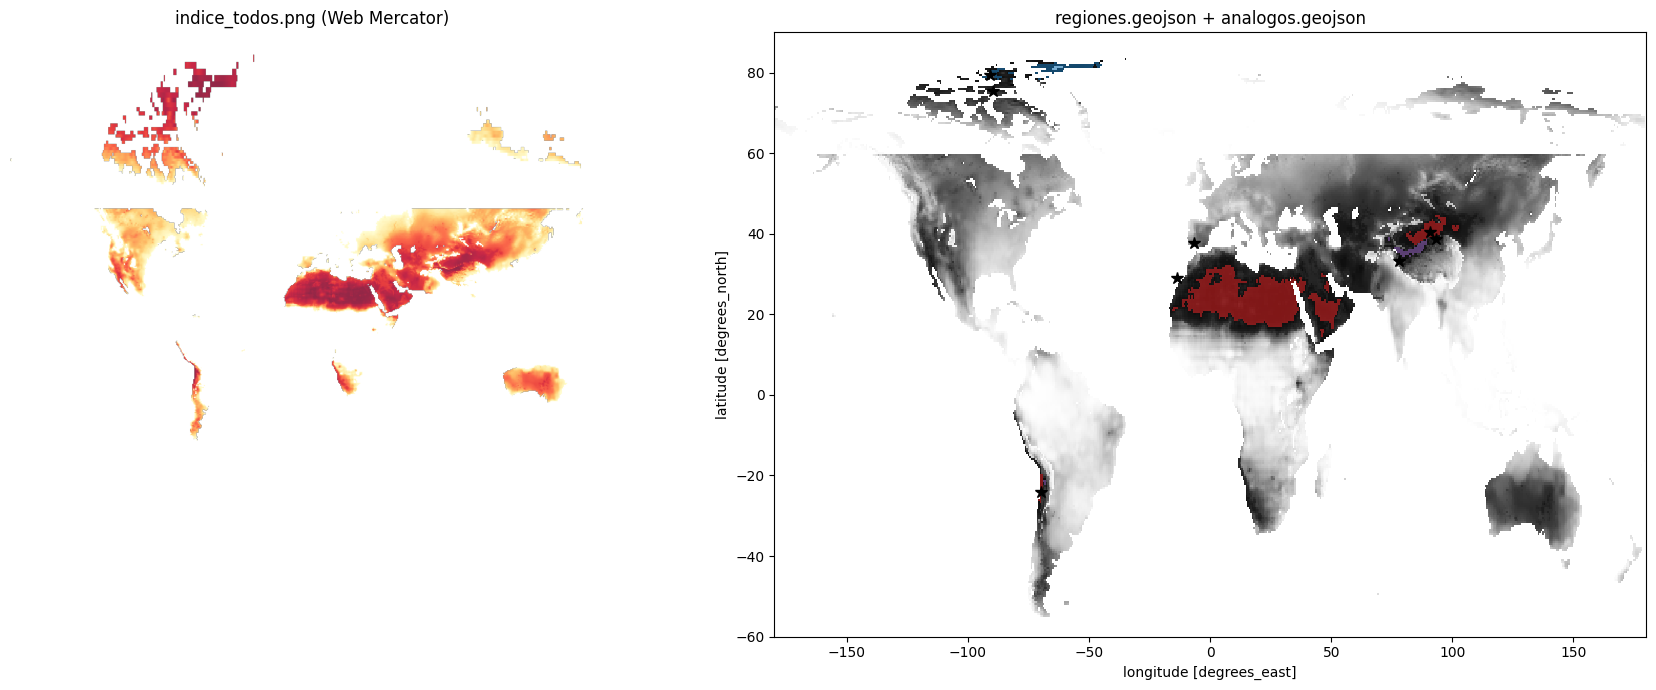

  LEEME.md                           1.2 KB
  analogos.geojson                  12.4 KB
  celdas.parquet                  1919.9 KB
  indice_marte_altura.png           10.3 KB
  indice_marte_arido.png            66.2 KB
  indice_marte_polar.png            13.3 KB
  indice_todos.png                  77.2 KB
  leyenda.json                       0.5 KB
  manifest.json                      3.2 KB
  regiones.geojson                  39.8 KB


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
# Izquierda: capa combinada en Web Mercator, como la verá el front
axes[0].imshow(Image.open(f"{WEB}/indice_todos.png"))
axes[0].set_title("indice_todos.png (Web Mercator)"); axes[0].axis("off")
# Derecha: polígonos de regiones y puntos de análogos sobre el percentil (lon/lat)
indices["pct_asignado"].plot(ax=axes[1], cmap="Greys", vmin=0, vmax=100, add_colorbar=False)
colores = {"marte_polar": "tab:blue", "marte_altura": "tab:purple", "marte_arido": "tab:red"}
for ft in features:
    g = ft["geometry"]
    polis = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    for poli in polis:
        x, y = zip(*poli[0])
        axes[1].fill(x, y, color=colores[ft["properties"]["perfil"]], alpha=0.6, lw=0)
for ft in features_a:
    x, y = ft["geometry"]["coordinates"]
    axes[1].plot(x, y, "k*", ms=9)
axes[1].set_title("regiones.geojson + analogos.geojson"); axes[1].set_xlim(-180, 180); axes[1].set_ylim(-60, 90)
plt.tight_layout(); plt.show()

for n in sorted(os.listdir(WEB)):
    print(f"  {n:28s} {os.path.getsize(f'{WEB}/{n}')/1e3:9.1f} KB")

## 8. Luna: carga
Versión activa en `04_resultados/version_activa_luna.json` (se crea con `luna_v0.3` si no existe).
Las regiones que se exportan son las **candidatas volcánicas**: percentil ≥ 95 del perfil satelital y ≥ 50 % de roca volcánica según GLiM.

In [ ]:
import warnings
ruta_activa_luna = f"{RESULTADOS}/version_activa_luna.json"
if not os.path.exists(ruta_activa_luna):
    with open(ruta_activa_luna, "w", encoding="utf-8") as f:
        json.dump({"version_activa": "luna_v0.3", "fecha": "2026-10-24",
                   "motivo": "validada con análogos (AUC 0,96) y con el mapa geológico GLiM (basalto ×7 en celdas ≥ p95)"},
                  f, ensure_ascii=False, indent=2)
VER_L = json.load(open(ruta_activa_luna, encoding="utf-8"))["version_activa"]
DIR_L, WEB_L = f"{RESULTADOS}/{VER_L}", f"{BASE}/06_web/{VER_L}"
os.makedirs(WEB_L, exist_ok=True)

ind_l = xr.open_dataset(f"{DIR_L}/indice_{VER_L}.nc").load()
reg_l = pd.read_csv(f"{DIR_L}/regiones_volcanicas_{VER_L}.csv", **LEER)
val_l = pd.read_csv(f"{DIR_L}/validacion_{VER_L}.csv", **LEER)
ref_l = pd.read_csv(f"{DIR_L}/puntos_referencia_luna.csv", **LEER)
registro_l = json.load(open(f"{DIR_L}/registro_{VER_L}.json", encoding="utf-8"))
glim = xr.open_dataset(f"{PROCESADOS}/glim_005.nc")
volc_l = sum(glim.frac.sel(clase=c).values.astype("uint16") for c in ["vb", "vi", "va", "py"]).clip(0, 100).astype("uint8")
la_l, lo_l = ind_l.lat.values, ind_l.lon.values
assert np.abs(glim.lat.values - la_l).max() < 1e-3, "GLiM y el índice Luna no comparten rejilla"
PASO_L = 180 / len(la_l)
pct_l = ind_l.luna_pct.transpose("lat", "lon").values
UMBRAL_L = registro_l["regiones"]["umbral_percentil"]

INFO_LUNA = {"nombre": "Luna (basalto)", "name_en": "Moon (basalt)",
             "descripcion": "Roca volcánica desnuda y pobre en cuarzo, como los mares basálticos lunares. "
                            "Candidatas: percentil ≥ 95 del índice de emisividad térmica y ≥ 50 % de roca volcánica según GLiM.",
             "description_en": "Bare, quartz-poor volcanic rock like the lunar basaltic maria. "
                               "Candidates: thermal-emissivity index ≥ 95th percentile and ≥ 50 % volcanic rock in the GLiM map."}
print(f"Luna: versión {VER_L} | {len(reg_l)} regiones candidatas | rejilla {len(la_l)}×{len(lo_l)} ({PASO_L:.2f}°)")

Luna: versión luna_v0.3 | 20 regiones candidatas | rejilla 3600×7200 (0.05°)


## 9. Luna: regiones, análogos, capa raster y celdas
Las regiones se reconstruyen etiquetando las celdas ≥ umbral del índice guardado. El índice se guardó redondeado a 0,01, así que
alguna región puede variar en una celda en el borde del umbral: si el número de celdas no coincide, se busca la región con
tamaño y centro más parecidos y se avisa.

In [ ]:
etq_l, n_l = ndimage.label(np.nan_to_num(pct_l, nan=0) >= UMBRAL_L, structure=np.ones((3, 3)))
ids_l = np.arange(1, n_l + 1)
tam_l = ndimage.sum(np.ones_like(pct_l), etq_l, ids_l)
cen_l = np.array(ndimage.center_of_mass(np.ones_like(pct_l), etq_l, ids_l))

def etiqueta_de(r):
    if r.region_id <= n_l and tam_l[r.region_id - 1] == r.n_celdas:
        return int(r.region_id)
    lat_c = la_l[0] + cen_l[:, 0] * PASO_L; lon_c = lo_l[0] + cen_l[:, 1] * PASO_L
    puntuacion = np.abs(tam_l - r.n_celdas) / r.n_celdas + np.hypot(lat_c - r.lat, lon_c - r.lon)
    k = int(np.argmin(puntuacion))
    print(f"  aviso: región {r.rango} reasignada por tamaño y centro ({int(tam_l[k])} celdas frente a {r.n_celdas})")
    assert puntuacion[k] < 0.5, f"No encuentro la región {r.rango} ({r.region})"
    return k + 1

features_l, etiqueta_a_id = [], {}
for r in reg_l.itertuples():
    e = etiqueta_de(r)
    ii, jj = np.nonzero(etq_l == e)
    celdas = [box(lo_l[j] - PASO_L / 2, la_l[i] - PASO_L / 2, lo_l[j] + PASO_L / 2, la_l[i] + PASO_L / 2) for i, j in zip(ii, jj)]
    geom = orientar(unary_union(celdas))
    k = int(np.nanargmax(pct_l[ii, jj]))
    etiqueta_a_id[e] = f"luna-{r.rango}"
    props = {"id": f"luna-{r.rango}", "perfil": "luna", **INFO_LUNA, "rango": int(r.rango), "region": r.region,
             "area_km2": r.area_km2, "n_celdas": r.n_celdas, "percentil_medio": r.percentil_medio,
             "mejor_celda": [round(float(lo_l[jj[k]]), 4), round(float(la_l[ii[k]]), 4)],
             "litologia_glim": r.litologia_glim, "glim_volcanica": r.glim_volcanica, "glim_basalto": r.glim_basalto,
             "glim_evaporitas": r.glim_evaporitas, "glim_carbonatos": r.glim_carbonatos,
             "contraste_espectral": r.contraste_medio, "analogo_conocido": r.analogo_conocido,
             "analogo_mas_cercano": r.referencia_mas_cercana, "distancia_analogo_km": r.distancia_km, "fuente": r.fuente}
    features_l.append({"type": "Feature", "geometry": redondear(geom), "properties": {k: limpio(v) for k, v in props.items()}})
with open(f"{WEB_L}/regiones.geojson", "w", encoding="utf-8") as f:
    json.dump({"type": "FeatureCollection", "features": features_l,
               "metadata": {"version": VER_L, "umbral_percentil": UMBRAL_L, "filtro": "glim_volcanica >= 0.5", "crs": "EPSG:4326"}},
              f, ensure_ascii=False, allow_nan=False)

# Análogos lunares y campos volcánicos de prueba (con su validación)
puntos_l = ref_l[ref_l.tipo.isin(["analogo_luna", "impacto", "volcanico_prueba"])].merge(
    val_l.drop(columns=["tipo", "verificacion"]), on="nombre", how="left")
features_al = []
for r in puntos_l.itertuples():
    props = {"nombre": r.nombre, "tipo": r.tipo, "verificacion": r.verificacion, "rasgo_analogo": r.motivo, "fuente": r.fuente,
             "percentil": r.percentil, "dist_celda_km": r.dist_celda_km, "celda_propia_excluida_por": r.celda_propia_excluida_por,
             "contraste_espectral": r.contraste, "glim_clase_celda": r.glim_clase_celda}
    features_al.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(float(r.lon), 4), round(float(r.lat), 4)]},
                        "properties": {k: limpio(v) for k, v in props.items()}})
with open(f"{WEB_L}/analogos.geojson", "w", encoding="utf-8") as f:
    json.dump({"type": "FeatureCollection", "features": features_al,
               "metadata": {"version": VER_L, "nota": "tipo volcanico_prueba = campo volcánico sin fuente como análogo lunar (prueba ciega)"}},
              f, ensure_ascii=False, allow_nan=False)

# Capa raster: máximo de cada bloque de 2×2 celdas (0,1°) y reproyección a Web Mercator
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    nf, nc = len(la_l) // 2, len(lo_l) // 2
    pct_g = np.nanmax(pct_l[:2 * nf, :2 * nc].reshape(nf, 2, nc, 2), axis=(1, 3))
la_g, lo_g = la_l[:2 * nf].reshape(nf, 2).mean(1), lo_l[:2 * nc].reshape(nc, 2).mean(1)
ANCHO_L = nc
y = np.pi * (1 - 2 * (np.arange(ANCHO_L) + 0.5) / ANCHO_L)
fi = np.clip(np.round((np.degrees(np.arctan(np.sinh(y))) - la_g[0]) / (2 * PASO_L)).astype(int), 0, nf - 1)
co = np.round((-180 + (np.arange(ANCHO_L) + 0.5) * 360 / ANCHO_L - lo_g[0]) / (2 * PASO_L)).astype(int) % nc
v = pct_g[np.ix_(fi, co)]
rgba = cmap(np.clip((v - PCT_MIN) / (100 - PCT_MIN), 0, 1))
rgba[..., 3] = np.where(np.isnan(v) | (v < PCT_MIN), 0, ALFA)
Image.fromarray((rgba * 255).astype(np.uint8), "RGBA").save(f"{WEB_L}/indice_luna.png", optimize=True)
with open(f"{WEB_L}/leyenda.json", "w", encoding="utf-8") as f:
    json.dump({**leyenda, "variable": "percentil del índice Luna (MI de CAMEL dentro del dominio desnudo)"}, f, ensure_ascii=False, indent=2)

# Celdas para el back: dominio con percentil >= 50
sel = np.nan_to_num(pct_l, nan=-1) >= 50
ii, jj = np.nonzero(sel)
df_l = pd.DataFrame({"lat": la_l[ii].astype("float32"), "lon": lo_l[jj].astype("float32"),
                     "percentil": pct_l[ii, jj].astype("float32"), "glim_volcanica_pct": volc_l[ii, jj]})
df_l["region_id"] = [etiqueta_a_id.get(int(e)) for e in etq_l[ii, jj]]
df_l.to_parquet(f"{WEB_L}/celdas.parquet", index=False)

print(f"regiones.geojson: {len(features_l)} | analogos.geojson: {len(features_al)} | indice_luna.png: {ANCHO_L}×{ANCHO_L} px "
      f"| celdas.parquet: {len(df_l):,} filas")
pd.DataFrame([ft["properties"] for ft in features_l])[["id", "region", "area_km2", "litologia_glim", "analogo_conocido"]]

/tmp/ipykernel_8603/212040769.py:65: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray((rgba * 255).astype(np.uint8), "RGBA").save(f"{WEB_L}/indice_luna.png", optimize=True)


regiones.geojson: 20 | analogos.geojson: 13 | indice_luna.png: 3600×3600 px | celdas.parquet: 348,748 filas


,id,region,area_km2,litologia_glim,analogo_conocido
0,luna-1,"Afar, Etiopía",51950.0,volcánica (basalto),No
1,luna-2,"Gobernacion de Rif Dimashq, Siria",21050.0,volcánica (basalto),No
2,luna-3,"Provincia de Medina, Arabia Saudita",12320.0,volcánica (basalto),Campo volcánico (sin fuente lunar)
3,luna-4,"Afar, Etiopía",7860.0,volcánica (basalto),No
4,luna-5,"Condado de Marsabit, Kenia",6500.0,volcánica (basalto),No
5,luna-6,"Provincia de La Meca, Arabia Saudita",5230.0,volcánica (basalto),No
6,luna-7,Islandia,4630.0,volcánica (basalto),Campo volcánico (sin fuente lunar)
7,luna-8,"Afar, Etiopía",4140.0,volcánica (basalto),No
8,luna-9,"Provincia de Tabuk, Arabia Saudita",4110.0,volcánica (basalto),No
9,luna-10,"Tibesti, Chad",4030.0,volcánica (basalto),No


## 10. Luna: manifest, LEEME y punto de entrada común

{
  "marte": {
    "version": "v1.3",
    "carpeta": "v1.3",
    "manifest": "v1.3/manifest.json"
  },
  "luna": {
    "version": "luna_v0.3",
    "carpeta": "luna_v0.3",
    "manifest": "luna_v0.3/manifest.json",
    "nombre": "Luna (basalto)",
    "name_en": "Moon (basalt)",
    "descripcion": "Roca volcánica desnuda y pobre en cuarzo, como los mares basálticos lunares. Candidatas: percentil ≥ 95 del índice de emisividad térmica y ≥ 50 % de roca volcánica según GLiM.",
    "description_en": "Bare, quartz-poor volcanic rock like the lunar basaltic maria. Candidates: thermal-emissivity index ≥ 95th percentile and ≥ 50 % volcanic rock in the GLiM map."
  }
}


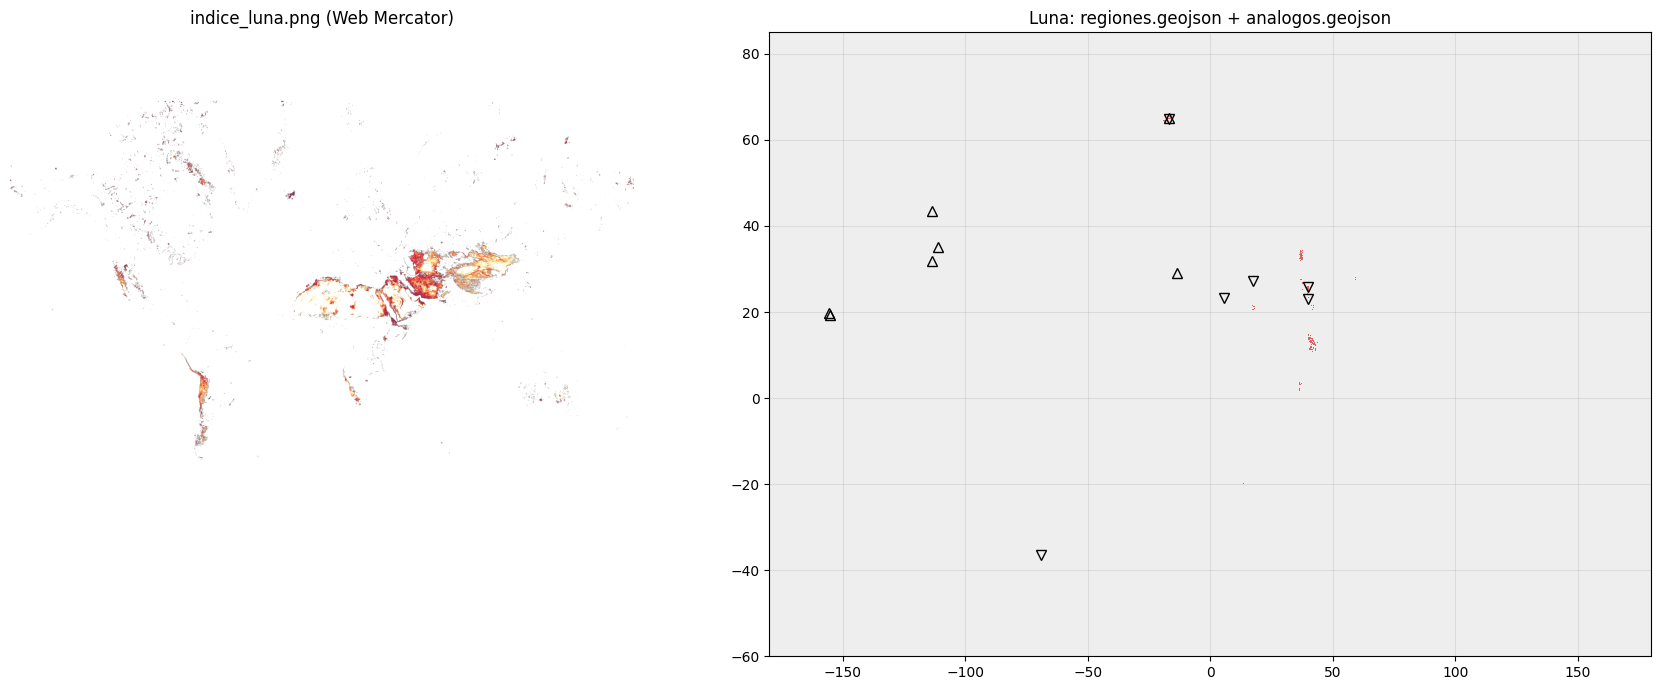

  LEEME.md                     0.7 KB
  analogos.geojson             6.2 KB
  celdas.parquet             835.5 KB
  indice_luna.png            506.2 KB
  leyenda.json                 0.5 KB
  manifest.json                4.0 KB
  regiones.geojson           193.8 KB


In [ ]:
def sin_nan(o):
    """JSON estricto: NaN -> null (JSON.parse del navegador no acepta NaN)."""
    if isinstance(o, dict): return {k: sin_nan(v) for k, v in o.items()}
    if isinstance(o, list): return [sin_nan(v) for v in o]
    if isinstance(o, (float, np.floating)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.integer): return int(o)
    return o

archivos_l = {n: {"bytes": os.path.getsize(f"{WEB_L}/{n}")} for n in sorted(os.listdir(WEB_L)) if n not in ("manifest.json", "LEEME.md")}
manifest_l = {
    "version": VER_L, "cuerpo": "luna",
    "generado": datetime.datetime.now().isoformat(timespec="seconds"),
    "proyecto": "NASA Space Apps 2026 - análogos terrestres de la Luna",
    "perfil": {**INFO_LUNA, "capa": "indice_luna.png"},
    "crs": {"geojson": "EPSG:4326 (lon, lat)", "png": "EPSG:3857 Web Mercator"},
    "png_limites": {"oeste": -180, "sur": -LAT_MAX_MERC, "este": 180, "norte": LAT_MAX_MERC},
    "regiones": {"archivo": "regiones.geojson", "umbral_percentil": UMBRAL_L, "filtro": "glim_volcanica >= 0.5",
                 "orden": "área", "nota": "analogo_conocido = Sí / Pendiente / Campo volcánico (sin fuente lunar) si hay un punto de referencia a <= 50 km"},
    "analogos": {"archivo": "analogos.geojson"},
    "celdas": {"archivo": "celdas.parquet", "resolucion": f"{PASO_L}° x {PASO_L}°",
               "nota": "solo celdas del dominio (suelo desnudo, sin nieve ni carbonatos) con percentil >= 50"},
    "leyenda": "leyenda.json",
    "validacion": {"resumen": registro_l["validacion"]["resumen"], "auc": registro_l["validacion"]["auc"],
                   "separacion_medianas": registro_l["validacion"]["separacion_medianas"],
                   "glim_enriquecimiento_p95": registro_l.get("glim", {}).get("enriquecimiento_p95")},
    "fuentes_datos": registro_l["datos"], "limitaciones": registro_l["limitaciones"] + [
        "carbonatos: ~19 % de la superficie del 10 % superior según GLiM (el filtro CI no los elimina del todo)",
        "evaporitas y salinas también puntúan alto; por eso las regiones exportadas se filtran con GLiM"],
    "archivos": archivos_l,
}
with open(f"{WEB_L}/manifest.json", "w", encoding="utf-8") as f:
    json.dump(sin_nan(manifest_l), f, ensure_ascii=False, indent=2, allow_nan=False)

leeme_l = f"""# Datos para la web · Luna · versión {VER_L}

- **Capa raster**: `indice_luna.png` (Web Mercator, mismos límites que Marte), percentil {PCT_MIN}–100; resto transparente.
- **Regiones**: `regiones.geojson`, {len(features_l)} candidatas volcánicas con `litologia_glim`, `glim_volcanica`, `area_km2`,
  `analogo_conocido` y `fuente`.
- **Análogos**: `analogos.geojson`, análogos lunares con fuente (`tipo` analogo_luna / impacto) y campos volcánicos de prueba,
  con su percentil y la clase GLiM de su celda.
- **Back**: `celdas.parquet` (lat, lon, percentil, glim_volcanica_pct, region_id), rejilla de {PASO_L}°.
- Las celdas son de ~5 km: describen el entorno, no un punto exacto.
"""
with open(f"{WEB_L}/LEEME.md", "w", encoding="utf-8") as f:
    f.write(leeme_l)

# Punto de entrada común: se mantiene el manifest de Marte (compatibilidad) y se añade el bloque "cuerpos"
ruta_entrada = f"{BASE}/06_web/manifest.json"
entrada = json.load(open(ruta_entrada, encoding="utf-8"))
entrada["cuerpos"] = {
    "marte": {"version": VER, "carpeta": VER, "manifest": f"{VER}/manifest.json"},
    "luna": {"version": VER_L, "carpeta": VER_L, "manifest": f"{VER_L}/manifest.json", **INFO_LUNA},
}
with open(ruta_entrada, "w", encoding="utf-8") as f:
    json.dump(sin_nan(entrada), f, ensure_ascii=False, indent=2, allow_nan=False)
print(json.dumps(entrada["cuerpos"], ensure_ascii=False, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(Image.open(f"{WEB_L}/indice_luna.png")); axes[0].set_title("indice_luna.png (Web Mercator)"); axes[0].axis("off")
axes[1].set_facecolor("#eeeeee")
for ft in features_l:
    g = ft["geometry"]
    for poli in ([g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]):
        x, yy = zip(*poli[0]); axes[1].fill(x, yy, color="tab:red", alpha=0.7, lw=0)
for ft in features_al:
    x, yy = ft["geometry"]["coordinates"]
    axes[1].plot(x, yy, "k^" if ft["properties"]["tipo"] != "volcanico_prueba" else "kv", ms=7, mfc="none")
axes[1].set_xlim(-180, 180); axes[1].set_ylim(-60, 85); axes[1].grid(alpha=0.3)
axes[1].set_title("Luna: regiones.geojson + analogos.geojson"); plt.tight_layout(); plt.show()
for n in sorted(os.listdir(WEB_L)):
    print(f"  {n:22s} {os.path.getsize(f'{WEB_L}/{n}')/1e3:9.1f} KB")

In [1]:
import json, zipfile
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

W = Path("/content/drive/MyDrive/Hackathon Nasa/06_web")
m = json.loads((W / "manifest.json").read_text(encoding="utf-8"))
carpetas = {v["carpeta"] for v in m.get("cuerpos", {}).values() if "carpeta" in v}
for capa in m.get("capas", {}).values():
    for k, v in capa.items():
        if k == "carpeta":
            carpetas.add(v)
        elif isinstance(v, str) and "/" in v:
            carpetas.add(v.split("/")[0])

destino = W.parent / "06_web_sync.zip"
n = total = 0
grandes = []
with zipfile.ZipFile(destino, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(W.rglob("*")):
        if not p.is_file():
            continue
        rel = p.relative_to(W)
        if len(rel.parts) == 1 or rel.parts[0] in carpetas:
            z.write(p, rel.as_posix())
            n += 1
            total += p.stat().st_size
            if p.stat().st_size > 20e6:
                grandes.append((rel.as_posix(), round(p.stat().st_size / 1e6, 1)))
print("Carpetas:", sorted(carpetas))
print(f"{n} archivos, {total/1e6:.1f} MB → {destino.name} ({destino.stat().st_size/1e6:.1f} MB comprimido)")
print("Archivos > 20 MB:", grandes or "ninguno")

Mounted at /content/drive
Carpetas: ['anortosita_v0', 'clima_v1', 'cuevas_v0', 'cuevas_v1', 'cuevas_v2', 'geologia_v0', 'hielo_v0', 'luna_v0.3', 'sitios_cuevas_v0', 'sitios_v0', 'topografia_sitios_v2', 'topografia_v2', 'v1.3']
32 archivos, 5.4 MB → 06_web_sync.zip (3.2 MB comprimido)
Archivos > 20 MB: ninguno
